In [ ]:
import numpy as np
import scipy.interpolate as si
import matplotlib.pyplot as plt

In [ ]:
def func(x,y):
    return np.sin(x) * np.sin(y)

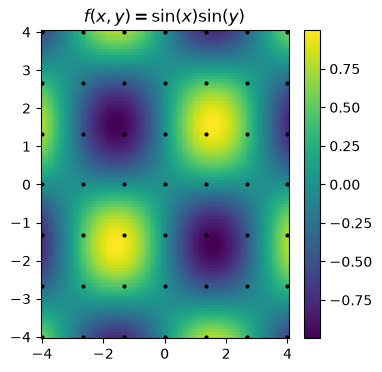

In [60]:
x = np.linspace(-4,4, 7)
y = np.linspace(-4,4, 7)
X,Y = np.meshgrid(x,y, indexing="ij")

xnew = np.linspace(-4,4, 101)
ynew = np.linspace(-4,4, 101)
Xnew, Ynew = np.meshgrid(xnew, ynew, indexing="ij")

fig,ax = plt.subplots(figsize=(4,4))
im = ax.pcolormesh(Xnew, Ynew, func(Xnew, Ynew))
ax.plot(X,Y, "ko", ms =2)
ax.set_title(r"$f(x,y)= \sin(x) \sin(y)$")

fig.colorbar(im, ax=ax)
plt.show()

method: linear, error: 8.697289959658216
method: cubic, error: 1.6451211566711679
method: pchip, error: 6.254663227673367


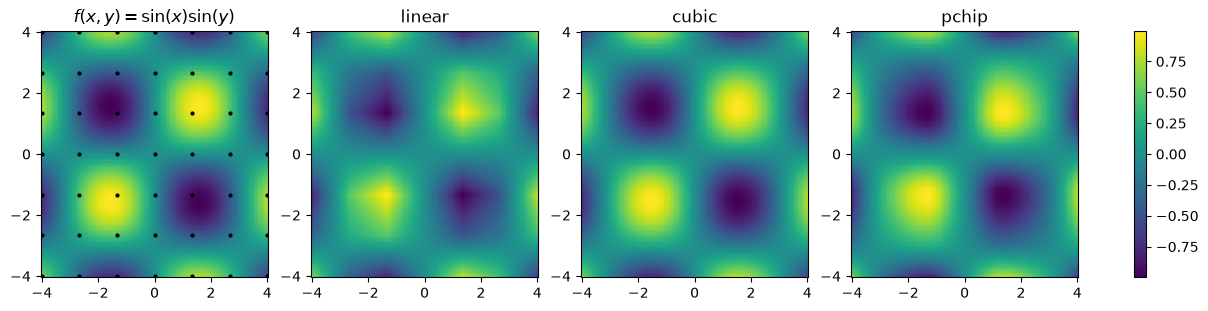

In [65]:
fig,ax = plt.subplots(1,4, figsize=(12,3), layout="constrained")

im = ax[0].pcolormesh(Xnew, Ynew, func(Xnew, Ynew))
ax[0].plot(X,Y, "ko", ms =2)
ax[0].set_title(r"$f(x,y)= \sin(x) \sin(y)$")

methods = ["linear", "cubic", "pchip"]
for axs, method in zip(ax[1:], methods):
    V = si.RegularGridInterpolator( (x,y), values = func(X,Y), method=method )
    axs.pcolormesh(Xnew, Ynew,V((Xnew, Ynew)) )
    axs.set_title(f"{method}")

    print(f"method: {method}, error: {100* np.mean(np.abs( func(Xnew, Ynew) - V((Xnew, Ynew)) ))}")

fig.colorbar(im, ax=ax)
plt.show()